# nb06 · L5 过程与相变路径

**目的**（`validation_methods_L0-L5.md` L5）：比较**给定温度程序下的路径**，而不只比较终态。

第一阶段做三件事：

1. 对现有的降温/升温路径运行同尺寸、同程序的 MLIP-MD；
2. 比较 RDF 峰、CN、四元环、四面体 Ge 和体积随时间/温度的变化；
3. 比较最终结构——按框架规定**不**计算晶化速度或成核率。

**为什么"只比终态"不够**：两条路径可以走到相似的终态却经历完全不同的中间过程。
补数据时该送哪些结构去算 DFT，取决于**偏离发生在哪里**——终态往往已经是后果而不是原因。
所以 L5 的主要输出是**首次偏离的位置**，不是终态误差。

参考是 phase-1 canonical 链上的两条程序，各 3 条独立副本：

| state | 程序 | 用途 |
|---|---|---|
| `canon_quench` | 1200 → 300 K，60 ps（15 K/ps，phase-1 正式淬火协议） | 第 1–8 节逐步走一遍 |
| `canon_heating` | 300 → 1200 K，25 ps | 第 9 节 |

> 每个偏离都要对照**同一指标在 AIMD 副本之间**的表现：如果三对副本之间也同样"偏离"，
> 这个偏离就不能归因于模型（`run_l5.py` 把这种情况写进 `failure_reason`）。

In [1]:
import os
# per-model results/data (results/models/<key>/); without it mlipeval falls back to the
# flat pre-2026-09 layout, which no longer holds current results
os.environ.setdefault("MLIPEVAL_MODEL", "mace_mpa0")
import sys, json
sys.path.insert(0, "../scripts")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mlipeval import datasets, paths
from mlipeval.l5_pathway import (
    PATHWAY_TOLERANCE_FLOORS, compare_pathway, divergence_band, first_divergence,
    temperature_programme, trace_pathway,
)
from mlipeval.plotting import use_style
from mlipeval.state_points import (
    CUTOFF_STATE, STATES, frozen_params, get_state, mlip_trajectory, production_segments,
    reference_production,
)
from mlipeval.thermo import temperature_series

use_style()
pd.set_option("display.width", 215)
pd.set_option("display.max_colwidth", 60)

## 1. 温度程序：参考与模型走的是同一条

程序（起止温度、时长）来自 state point 定义，与参考链的 INCAR 一致；下面再从两侧轨迹的动能温度
各测一遍，确认两边实际走过的是同一条程序。

参考: {"name": "aimd_canon_quench_r1", "n_frames": 2000, "n_atoms": 306, "composition": "Ge68Sb68Te170", "volume_A3": 9902.9123, "number_density_at_per_A3": 0.0309, "timestep_fs": 3.0, "sample_stride": 10, "protocol_id": "gst225_aimd_canonical_v1:H4_mq_s01_03_quench1200_300", "source": "$MLIPEVAL_WORKSPACE/phase1_vasp_inputs_20260828/H4_mq_s01_03_quench1200_300/runs/run_AhiIAh40FH/XDATCAR"}
模型: {"name": "mlip_canon_quench", "n_frames": 2001, "n_atoms": 306, "composition": "Ge68Sb68Te170", "volume_A3": 9902.9123, "number_density_at_per_A3": 0.0309, "timestep_fs": 3.0, "sample_stride": 10, "protocol_id": "mlip_md_canon_quench_seed0", "source": "$MLIPEVAL_WORKSPACE/eval_framework/data/models/mace_mpa0/md_canon_quench__lammps.npz"}


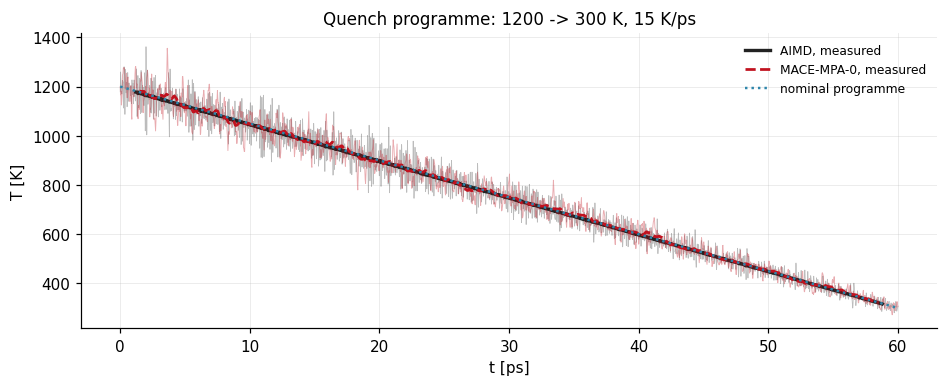

In [2]:
st = get_state("canon_quench")
PROGRAMME = st.programme
segments = production_segments(st)
reference, model = segments["reference"], segments["model"]
print("参考:", json.dumps(reference.describe(), ensure_ascii=False))
print("模型:", json.dumps(model.describe(), ensure_ascii=False))

# the reference is read at the sampling stride; the temperature needs every MD step
from mlipeval.state_points import reference_trajectory
series_ref = temperature_series(reference_trajectory(st, replica=1, stride=1))
fig, ax = plt.subplots(figsize=(8.5, 3.4))
ax.plot(series_ref.time_fs / 1000.0, series_ref.temperature, lw=0.5, alpha=0.3, color="#222222")
win = max(1, len(series_ref.temperature) // 50)
smooth = np.convolve(series_ref.temperature, np.ones(win) / win, mode="same")
ax.plot(series_ref.time_fs[win:-win] / 1000.0, smooth[win:-win], lw=2.2, color="#222222", label="AIMD, measured")
if model.temperatures is not None:
    ax.plot(model.frame_time_fs / 1000.0, model.temperatures, lw=0.6, alpha=0.35, color="#c1121f")
    wm = max(1, len(model.temperatures) // 40)
    sm = np.convolve(model.temperatures, np.ones(wm) / wm, mode="same")
    ax.plot(model.frame_time_fs[wm:-wm] / 1000.0, sm[wm:-wm], lw=1.8, ls="--",
            color="#c1121f", label="MACE-MPA-0, measured")
nominal = temperature_programme(60, PROGRAMME)
ax.plot(np.linspace(0, PROGRAMME[0][0] / 1000.0, 60), nominal, ":", lw=1.6,
        color="#2e86ab", label="nominal programme")
rate = (PROGRAMME[0][1] - PROGRAMME[0][2]) / (PROGRAMME[0][0] / 1000)
ax.set_xlabel("t [ps]"); ax.set_ylabel("T [K]")
ax.set_title(f"Quench programme: {PROGRAMME[0][1]:.0f} -> {PROGRAMME[0][2]:.0f} K, {rate:.0f} K/ps")
ax.legend(fontsize=8)
plt.show()

## 2. 冻结分析参数

降温路径横跨 1200 K 到 300 K，沿途 RDF 第一极小的深度一直在变——**没有单一的良定义极小**
（nb04 第 7 节展示的高温退化）。所以截断取自等温末态（`canon_amorphous_300K` 状态点，
三副本合并），然后对整条路径冻结，并显式记录在结果的 `cutoff_provenance` 里。

In [3]:
params, _ = frozen_params(CUTOFF_STATE)
display(pd.Series(params.bond_cutoffs).to_frame("冻结截断 (A)").round(3))
print("来源:", params.provenance)

,冻结截断 (A)
Ge-Ge,3.163
Ge-Sb,3.213
Ge-Te,3.538
Sb-Sb,3.463
Sb-Te,3.888
Te-Te,3.188


来源: first minimum of the partial RDF of 'aimd_canon_amorphous_300K_pooled' (protocol_id=gst225_aimd_canonical_v1:H4_mq_s01_04_nvt300, 1002 frames, stride=1, search window 1.8-4.5 A, peak_rule=first)


## 3. 容差不能拍脑袋定：用参考自身的涨落

第一版用的是硬编码容差（例如 Ge–Te RDF 首峰 0.08 Å）。这个判据是错的——
**参考自己**的首峰位置在相邻取样点之间就在 2.69–2.94 Å 之间跳，单帧散布 (~0.25 Å) 比容差大三倍，
于是"偏离"检测出来的全是噪声。

现在的做法：

1. 每个取样点把观测量在 `average_window` 帧内平均；
2. 用窗口内的标准差作为**参考自身的涨落尺度** σ；
3. 容差带 = `sigma_factor × σ`（并设一个下限，防止 σ 偶然过小把带压成零）；
4. 连续 `consecutive` 个点越界才算偏离，单点噪声不算。

In [4]:
report = compare_pathway(reference, params, model_traj=model, n_samples=40,
                         average_window=8, sigma_factor=3.0,
                         segments=PROGRAMME, state_label=st.name)
ref_t, mod_t = report.trace_ref, report.trace_model
print(f"取样点 {len(ref_t.progress)} 个，每点平均 {ref_t.average_window} 帧；产出 metric {len(report.results)} 条")

display(pd.DataFrame({
    "参考自身散布 σ (均值)": {k: float(np.nanmean(v)) for k, v in ref_t.std.items() if k in report.bands},
    "容差带 3σ (均值)": {k: float(np.nanmean(v)) for k, v in report.bands.items()},
    "硬编码下限": {k: PATHWAY_TOLERANCE_FLOORS.get(k) for k in report.bands},
}).round(4))

取样点 40 个，每点平均 8 帧；产出 metric 16 条


,参考自身散布 σ (均值),容差带 3σ (均值),硬编码下限
mean_cn_all,0.0451,0.1354,0.05
mean_cn_Ge,0.0748,0.2246,0.08
mean_cn_Sb,0.0769,0.2308,0.08
mean_cn_Te,0.0483,0.1470,0.08
four_rings_per_atom,0.0415,0.1244,0.02
tetrahedral_fraction,0.0272,0.0817,0.02
rdf_first_peak_A,0.0411,0.1278,0.03
volume_per_atom_A3,0.0000,0.0100,0.01


## 4. 沿路径追踪结构观测量

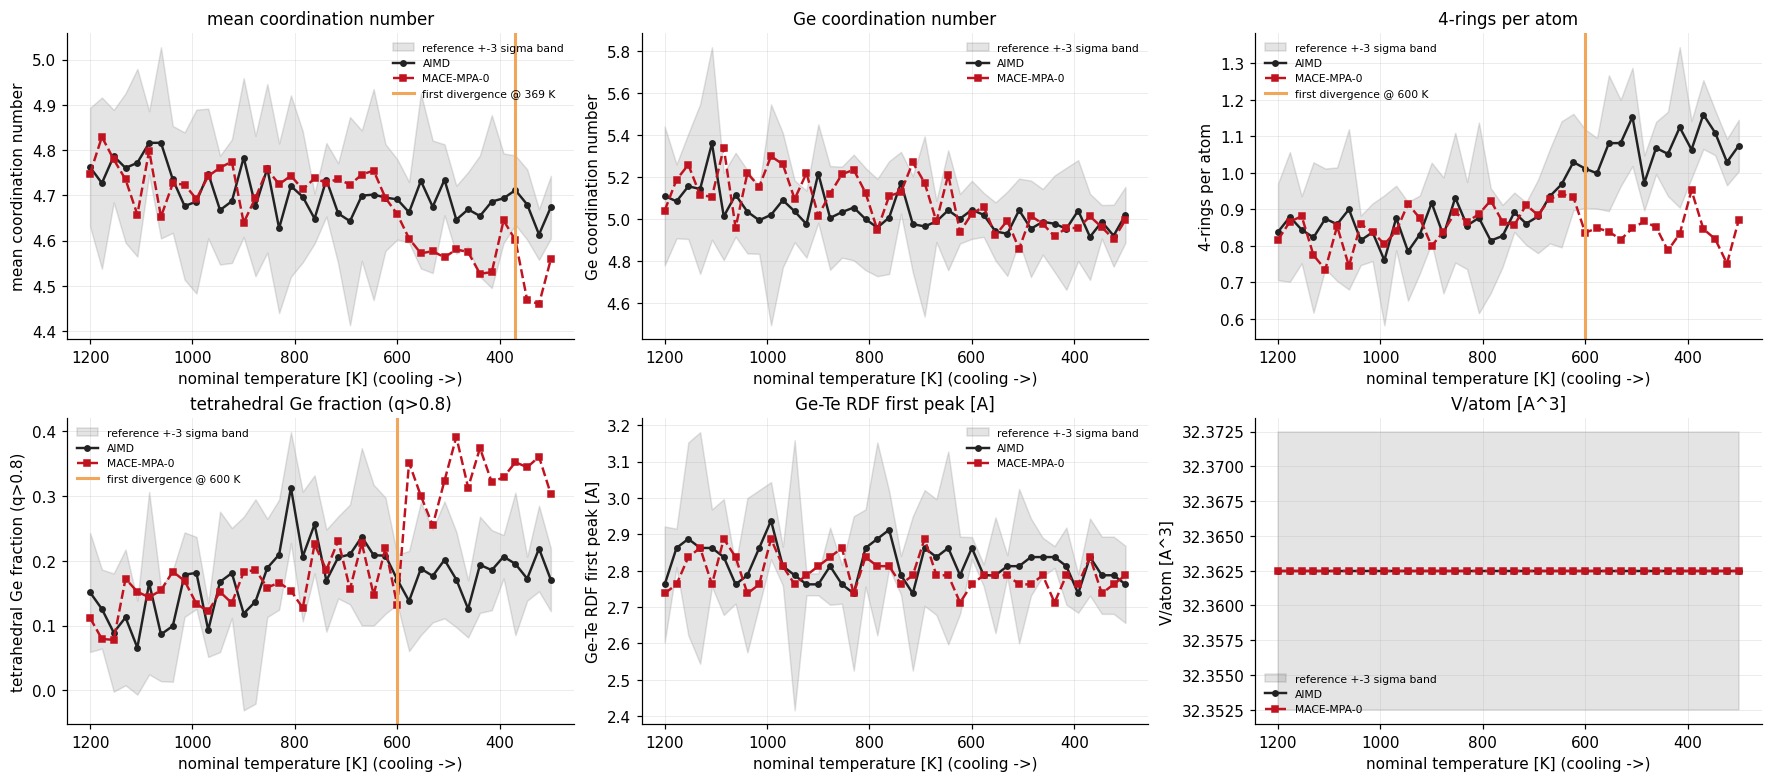

In [5]:
observables = [
    ("mean_cn_all", "mean coordination number"),
    ("mean_cn_Ge", "Ge coordination number"),
    ("four_rings_per_atom", "4-rings per atom"),
    ("tetrahedral_fraction", "tetrahedral Ge fraction (q>0.8)"),
    ("rdf_first_peak_A", "Ge-Te RDF first peak [A]"),
    ("volume_per_atom_A3", "V/atom [A^3]"),
]
T = ref_t.nominal_temperature
fig, axes = plt.subplots(2, 3, figsize=(16, 7))
for ax, (key, label) in zip(axes.flat, observables):
    band = report.bands[key]
    ax.fill_between(T, ref_t.values[key] - band, ref_t.values[key] + band,
                    color="#222222", alpha=0.12, label="reference +-3 sigma band")
    ax.plot(T, ref_t.values[key], "o-", ms=3.5, color="#222222", label="AIMD")
    ax.plot(T, mod_t.values[key], "s--", ms=3.5, color="#c1121f", label="MACE-MPA-0")
    div = report.divergences.get(key, {})
    if div.get("progress") is not None:
        ax.axvline(T[int(div["index"])], color="#f2a65a", lw=2.0,
                   label=f"first divergence @ {T[int(div['index'])]:.0f} K")
    ax.invert_xaxis()
    ax.set_xlabel("nominal temperature [K] (cooling ->)"); ax.set_ylabel(label); ax.set_title(label)
    ax.legend(fontsize=7)
plt.show()

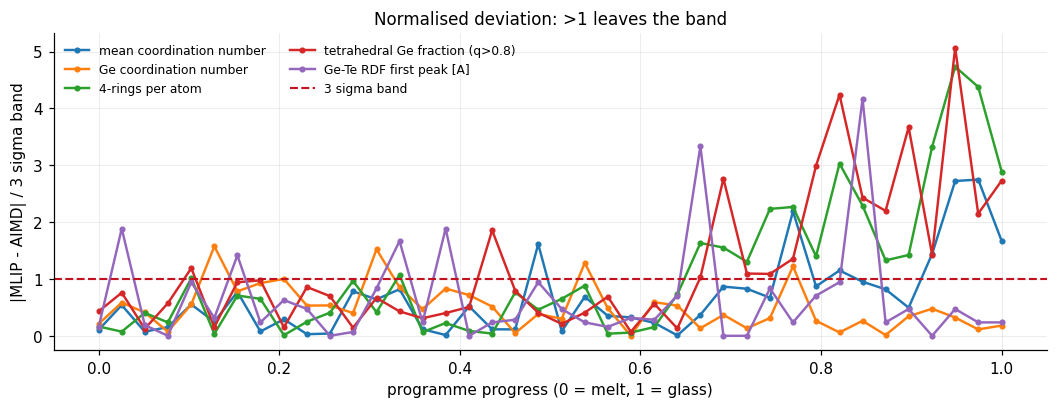

,观测量,首次偏离进度,对应温度 (K),参考帧号,max |偏差|,max 偏差 (σ)
0,mean_cn_all,0.9230,369.2308,1845.0,0.2116,2.7481
1,mean_cn_Ge,NaN,NaN,NaN,0.3272,1.5736
2,mean_cn_Sb,0.9485,346.1538,1896.0,0.3070,2.1582
3,mean_cn_Te,0.6918,576.9231,1383.0,0.2574,3.0515
4,four_rings_per_atom,0.6663,600.0000,1332.0,0.3137,4.7323
5,tetrahedral_fraction,0.6663,600.0000,1332.0,0.2202,5.0665
6,rdf_first_peak_A,NaN,NaN,NaN,0.1250,4.1667
7,volume_per_atom_A3,NaN,NaN,NaN,0.0000,0.0000


In [6]:
fig, ax = plt.subplots(figsize=(9.5, 3.6))
for key, label in observables:
    if key == "volume_per_atom_A3":
        continue
    delta = np.abs(mod_t.values[key] - ref_t.values[key])
    ax.plot(ref_t.progress, delta / report.bands[key], "o-", ms=3, label=label)
ax.axhline(1.0, color="#c1121f", ls="--", lw=1.4, label="3 sigma band")
ax.set_xlabel("programme progress (0 = melt, 1 = glass)"); ax.set_ylabel("|MLIP - AIMD| / 3 sigma band")
ax.set_title("Normalised deviation: >1 leaves the band"); ax.legend(fontsize=8, ncol=2)
plt.show()

display(pd.DataFrame([{
    "观测量": key,
    "首次偏离进度": div["progress"],
    "对应温度 (K)": T[int(div["index"])] if div.get("index") is not None else None,
    "参考帧号": int(ref_t.frame_index[int(div["index"])]) if div.get("index") is not None else None,
    "max |偏差|": div["max_delta"],
    "max 偏差 (σ)": div["max_normalised"],
} for key, div in report.divergences.items()]).round(4))

## 5. 关键对照：这些偏离是模型误差，还是链间涨落？

上一节的 σ 是**同一条轨迹内的热涨落**，不是**链与链之间的差异**。两条起点相同、物理完全相同的淬火，
仅仅因为随机初速就会互相偏离。现在两侧都有独立的链，可以把三种距离放在一起：

| 对照 | 含义 |
|---|---|
| MLIP(seed0) vs AIMD(r1) | 待评的模型–参考距离 |
| MLIP(seed0) vs MLIP(seed1) | 同一模型的链间涨落 |
| AIMD(r1) vs AIMD(r2) | **参考自身**的链间涨落——模型能做到的最好水平 |

模型–参考距离显著大于两种链间涨落，才提示真实的模型误差。

In [7]:
seeds = st.available_seeds()
print("已有的 MLIP 淬火种子:", seeds, "  AIMD 副本:", st.n_replicas)

model_b = mlip_trajectory(st, seed=seeds[1])
trace_b = trace_pathway(model_b, params, n_samples=40, average_window=8,
                        segments=PROGRAMME, name=f"MLIP seed{seeds[1]}")
trace_r2 = trace_pathway(reference_production(st, 2), params, n_samples=40, average_window=8,
                         segments=PROGRAMME, name="AIMD replica 2")
rows = []
for key, _ in observables:
    band = report.bands[key]
    d_model = np.nanmax(np.abs(mod_t.values[key] - ref_t.values[key]))
    d_seed = np.nanmax(np.abs(trace_b.values[key] - mod_t.values[key]))
    d_repl = np.nanmax(np.abs(trace_r2.values[key] - ref_t.values[key]))
    rows.append({
        "observable": key,
        "MLIP vs AIMD  max|Δ|": float(d_model),
        "MLIP vs MLIP  max|Δ|": float(d_seed),
        "AIMD vs AIMD  max|Δ|": float(d_repl),
        "模型/副本 比值": float(d_model / max(d_repl, 1e-12)),
        "3σ 带": float(np.nanmean(band)),
    })
control = pd.DataFrame(rows)
display(control.round(4))
print("比值 ≈ 1：该观测量上的『偏离』与两条独立 AIMD 之间的差同量级，无法归因于模型；")
print("比值明显 > 1 才提示真实的模型误差。")

已有的 MLIP 淬火种子: [0, 1, 2]   AIMD 副本: 3


,observable,MLIP vs AIMD max|Δ|,MLIP vs MLIP max|Δ|,AIMD vs AIMD max|Δ|,模型/副本 比值,3σ 带
0,mean_cn_all,0.2116,0.1863,0.2042,1.0360,0.1354
1,mean_cn_Ge,0.3272,0.3180,0.3033,1.0788,0.2246
2,four_rings_per_atom,0.3137,0.2835,0.3276,0.9576,0.1244
3,tetrahedral_fraction,0.2202,0.1353,0.1423,1.5469,0.0817
4,rdf_first_peak_A,0.1250,0.1250,0.2250,0.5556,0.1278
5,volume_per_atom_A3,0.0000,0.0000,0.0000,0.0000,0.0100


比值 ≈ 1：该观测量上的『偏离』与两条独立 AIMD 之间的差同量级，无法归因于模型；
比值明显 > 1 才提示真实的模型误差。


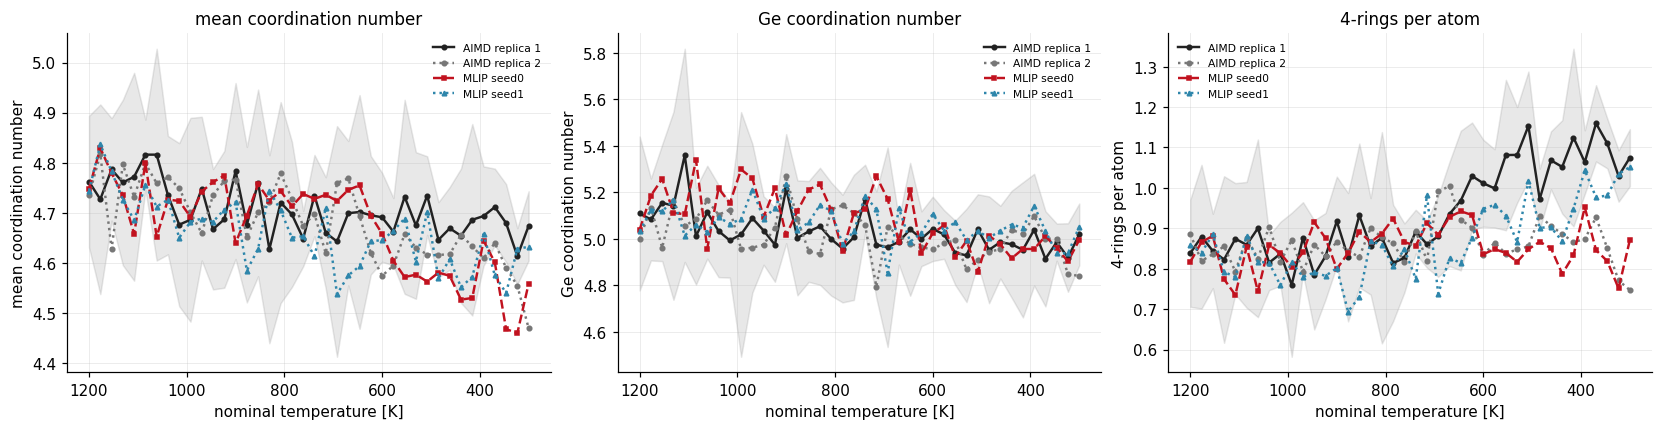

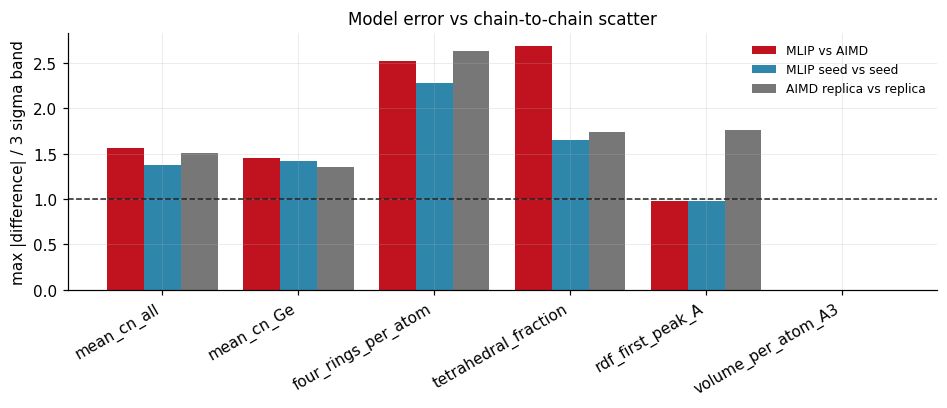

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (key, label) in zip(axes, observables[:3]):
    ax.fill_between(T, ref_t.values[key] - report.bands[key], ref_t.values[key] + report.bands[key],
                    color="#222222", alpha=0.10)
    ax.plot(T, ref_t.values[key], "o-", ms=3, color="#222222", label="AIMD replica 1")
    ax.plot(T, trace_r2.values[key], "o:", ms=3, color="#777777", label="AIMD replica 2")
    ax.plot(T, mod_t.values[key], "s--", ms=3, color="#c1121f", label="MLIP seed0")
    ax.plot(T, trace_b.values[key], "^:", ms=3, color="#2e86ab", label="MLIP seed1")
    ax.invert_xaxis(); ax.set_xlabel("nominal temperature [K]"); ax.set_ylabel(label)
    ax.set_title(label); ax.legend(fontsize=7)
plt.show()

fig, ax = plt.subplots(figsize=(8.5, 3.6))
x = np.arange(len(control)); w = 0.27
for j, (col, color, lab) in enumerate((("MLIP vs AIMD  max|Δ|", "#c1121f", "MLIP vs AIMD"),
                                       ("MLIP vs MLIP  max|Δ|", "#2e86ab", "MLIP seed vs seed"),
                                       ("AIMD vs AIMD  max|Δ|", "#777777", "AIMD replica vs replica"))):
    ax.bar(x + (j - 1) * w, control[col] / control["3σ 带"], w, color=color, label=lab)
ax.axhline(1.0, color="#222", ls="--", lw=1.0)
ax.set_xticks(x); ax.set_xticklabels(control["observable"], rotation=30, ha="right")
ax.set_ylabel("max |difference| / 3 sigma band"); ax.set_title("Model error vs chain-to-chain scatter")
ax.legend(fontsize=8)
plt.show()

## 6. 终态比较

终态仍然要比，但它只是路径的一个切片。每条终态误差都附带"是否落在参考自身散布之内"。

In [9]:
final_rows = []
for r in report.results:
    if "final_state_error" in r.metric_id:
        e = r.extra or {}
        final_rows.append({"观测量": r.metric_id.split(".")[2],
                           "AIMD 终态": e.get("reference_final"),
                           "MLIP 终态": e.get("model_final"),
                           "差值": r.value,
                           "参考终态 σ": e.get("reference_sigma_final"),
                           "落在参考散布内": e.get("within_reference_scatter")})
display(pd.DataFrame(final_rows).round(4))

,观测量,AIMD 终态,MLIP 终态,差值,参考终态 σ,落在参考散布内
0,mean_cn_all,4.6740,4.5588,-0.1152,0.0230,False
1,mean_cn_Ge,5.0184,4.9945,-0.0239,0.0443,True
2,mean_cn_Sb,5.7923,5.7849,-0.0074,0.0419,True
3,mean_cn_Te,4.0890,3.8941,-0.1949,0.0284,False
4,four_rings_per_atom,1.0748,0.8709,-0.2038,0.0235,False
5,tetrahedral_fraction,0.1707,0.3030,0.1323,0.0162,False
6,rdf_first_peak_A,2.7625,2.7875,0.0250,0.0354,True
7,volume_per_atom_A3,32.3625,32.3625,0.0000,0.0000,True


## 7. 偏离点附近的连续帧：只展示，不导出

框架 6 节对 L5 类失败的要求写得很具体：**"首次偏离前后的连续帧，而不是只取最终异常帧"**。
`collect_from_l5` 就是按这条实现的，每一条都带上偏离来源、选择理由、建议协议与需要回归的 metric ID。

**但这里不写出候选文件。** 这些帧来自 canonical AIMD 链本身，而 L0 的 `protected_audit`（H5）
正是从同一批链上抽的。把偏离窗口送去补算，就可能把 H5 帧的近邻帧加进训练集，
让 H5 不再是独立的考卷。在 `collect_from_l5` 能按 H5 的源帧号排除近邻之前，
补算候选只从 L0 诊断集导出（nb01 第 9 节）。下面只重放选择过程，并列出 H5 在这条链上的源帧。

In [10]:
from mlipeval.calculators import model_spec_only
from mlipeval.failure_export import collect_from_l5, deduplicate

candidates, structures = collect_from_l5(report, reference, window=3)
print(f"偏离窗口内收集到 {len(candidates)} 帧")
if candidates:
    candidate_set = deduplicate(candidates, structures, model_spec_only(), min_distance=0.02)
    print(f"去重后 {len(candidate_set)} 帧   方法: {candidate_set.dedup_method}")
    display(pd.DataFrame([c.to_dict() for c in candidate_set.candidates])[
        ["candidate_id", "source_metric", "reason", "cluster_size", "novelty", "suggested_protocol"]
    ].round(4))

h5 = datasets.labelled_h5()
same_chain = (h5.tags["seed"] == 1) & (h5.tags["pool"] == "quench")
print(f"\nH5 里取自本链（副本 1 淬火段）的帧: {int(same_chain.sum())} 帧，"
      f"源帧号 {sorted(int(f) for f in h5.tags['source_frame'][same_chain])}")
print("=> 不导出：这些偏离窗口与 protected_audit 的来源是同一条轨迹。")

偏离窗口内收集到 35 帧
去重后 14 帧   方法: window-level de-duplication on MACE descriptors (min distance 0.02); 5 windows -> 2 kept, each retained in full


,candidate_id,source_metric,reason,cluster_size,novelty,suggested_protocol
0,L5_mean_cn_all_f01842,L5.pathway.mean_cn_all.first_divergence_progress,mean_cn_all leaves the reference band at progress 0.92,7,0.0232,gst225_pbe_canonical_v1 static on a continuous window
1,L5_mean_cn_all_f01843,L5.pathway.mean_cn_all.first_divergence_progress,mean_cn_all leaves the reference band at progress 0.92,7,0.0232,gst225_pbe_canonical_v1 static on a continuous window
2,L5_mean_cn_all_f01844,L5.pathway.mean_cn_all.first_divergence_progress,mean_cn_all leaves the reference band at progress 0.92,7,0.0232,gst225_pbe_canonical_v1 static on a continuous window
3,L5_mean_cn_all_f01845,L5.pathway.mean_cn_all.first_divergence_progress,mean_cn_all leaves the reference band at progress 0.92,7,0.0232,gst225_pbe_canonical_v1 static on a continuous window
4,L5_mean_cn_all_f01846,L5.pathway.mean_cn_all.first_divergence_progress,mean_cn_all leaves the reference band at progress 0.92,7,0.0232,gst225_pbe_canonical_v1 static on a continuous window
5,L5_mean_cn_all_f01847,L5.pathway.mean_cn_all.first_divergence_progress,mean_cn_all leaves the reference band at progress 0.92,7,0.0232,gst225_pbe_canonical_v1 static on a continuous window
6,L5_mean_cn_all_f01848,L5.pathway.mean_cn_all.first_divergence_progress,mean_cn_all leaves the reference band at progress 0.92,7,0.0232,gst225_pbe_canonical_v1 static on a continuous window
7,L5_mean_cn_Te_f01380,L5.pathway.mean_cn_Te.first_divergence_progress,mean_cn_Te leaves the reference band at progress 0.69,7,0.0232,gst225_pbe_canonical_v1 static on a continuous window
8,L5_mean_cn_Te_f01381,L5.pathway.mean_cn_Te.first_divergence_progress,mean_cn_Te leaves the reference band at progress 0.69,7,0.0232,gst225_pbe_canonical_v1 static on a continuous window
9,L5_mean_cn_Te_f01382,L5.pathway.mean_cn_Te.first_divergence_progress,mean_cn_Te leaves the reference band at progress 0.69,7,0.0232,gst225_pbe_canonical_v1 static on a continuous window



H5 里取自本链（副本 1 淬火段）的帧: 5 帧，源帧号 [1999, 4399, 11999, 15199, 19599]
=> 不导出：这些偏离窗口与 protected_audit 的来源是同一条轨迹。


## 8. 全部 L5 结果

In [11]:
frame = report.results.to_frame()
display(frame)
print("状态分布:", frame.status.value_counts().to_dict())
print("\n带定义:", report.results.context["band_definition"])

,metric_id,value,unit,status,tier,grade,z_eff
0,L5.pathway.mean_cn_all.first_divergence_progress@canon_q...,0.922961,fraction of programme,failed,A,ungraded,None
1,L5.pathway.mean_cn_all.final_state_error@canon_quench,-0.115196,-,provisional,A,ungraded,None
2,L5.pathway.mean_cn_Ge.first_divergence_progress@canon_qu...,NaN,fraction of programme,provisional,A,ungraded,None
3,L5.pathway.mean_cn_Ge.final_state_error@canon_quench,-0.023897,-,provisional,A,ungraded,None
4,L5.pathway.mean_cn_Sb.first_divergence_progress@canon_qu...,0.948474,fraction of programme,failed,A,ungraded,None
5,L5.pathway.mean_cn_Sb.final_state_error@canon_quench,-0.007353,-,provisional,A,ungraded,None
6,L5.pathway.mean_cn_Te.first_divergence_progress@canon_qu...,0.691846,fraction of programme,failed,A,ungraded,None
7,L5.pathway.mean_cn_Te.final_state_error@canon_quench,-0.194853,-,provisional,A,ungraded,None
8,L5.pathway.four_rings_per_atom.first_divergence_progress...,0.666333,fraction of programme,failed,A,ungraded,None
9,L5.pathway.four_rings_per_atom.final_state_error@canon_q...,-0.203840,-,provisional,A,ungraded,None


状态分布: {'provisional': 11, 'failed': 5}

带定义: tolerance = max(sigma_factor * within-window std of the reference, floor)


## 9. 两条程序的三副本判级，以及升温路径

`run_l5.py` 对两条程序各做三对配对，并把 AIMD 副本之间的同一指标作为对照：

- **终态误差**（`final_state_error`）用副本间 RMS 作 `sigma_ref` 正式判级；
- **首次偏离**（`first_divergence_progress`）不判级，但当三对副本之间也同样越界时，
  `failure_reason` 会写明"不可归因于模型"。

grade                                    A  B  ungraded
state         kind                                     
canon_heating final_state_error          6  1         1
              first_divergence_progress  0  0         8
canon_quench  final_state_error          7  0         1
              first_divergence_progress  0  0         8

,state,observable,value,status,failure_reason
0,canon_quench,mean_cn_all,0.684,provisional,"3/3 model pairs fail, but so do 3/3 AIMD replica pairs: ..."
2,canon_quench,mean_cn_Ge,0.231,provisional,"1/3 model pairs fail, but so do 1/3 AIMD replica pairs: ..."
4,canon_quench,mean_cn_Sb,0.756,failed,2/3 replica pairs: model leaves the 3-sigma reference ba...
6,canon_quench,mean_cn_Te,0.525,provisional,"2/3 model pairs fail, but so do 3/3 AIMD replica pairs: ..."
8,canon_quench,four_rings_per_atom,0.555,provisional,"3/3 model pairs fail, but so do 3/3 AIMD replica pairs: ..."
10,canon_quench,tetrahedral_fraction,0.666,provisional,"1/3 model pairs fail, but so do 2/3 AIMD replica pairs: ..."
12,canon_quench,rdf_first_peak_A,0.410,failed,2/3 replica pairs: model leaves the 3-sigma reference ba...
14,canon_quench,volume_per_atom_A3,NaN,provisional,
16,canon_heating,mean_cn_all,0.025,provisional,"1/3 model pairs fail, but so do 2/3 AIMD replica pairs: ..."
18,canon_heating,mean_cn_Ge,0.256,provisional,"1/3 model pairs fail, but so do 1/3 AIMD replica pairs: ..."


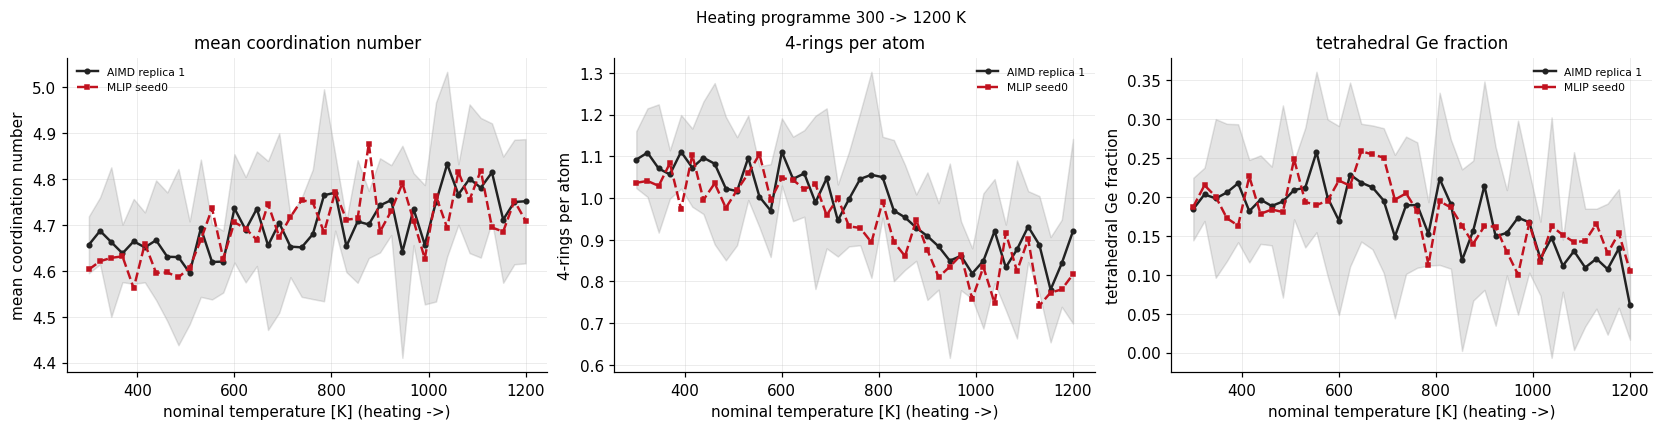

In [12]:
rows = []
for name in ("canon_quench", "canon_heating"):
    path = paths.result_path(f"L5_{name}__lammps.json")
    for r in json.loads(path.read_text())["results"]:
        obs, kind = r["metric_id"].split("@")[0].split(".")[2:4]
        rows.append({"state": name, "observable": obs, "kind": kind, "value": r["value"],
                     "sigma_ref": r["uncertainty"], "z_eff": r["z_eff"], "grade": r["grade"],
                     "status": r["status"], "failure_reason": (r["failure_reason"] or "")[:90]})
l5 = pd.DataFrame(rows)
display(pd.crosstab([l5.state, l5.kind], l5.grade))
display(l5[l5.kind == "first_divergence_progress"][["state", "observable", "value", "status", "failure_reason"]]
        .round(3))

from mlipeval import crossmodel as cm
from mlipeval.models import current_key
heat = cm.load_npz(current_key(), "l5_canon_heating.npz")
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, (key, label) in zip(axes, [("mean_cn_all", "mean coordination number"),
                                   ("four_rings_per_atom", "4-rings per atom"),
                                   ("tetrahedral_fraction", "tetrahedral Ge fraction")]):
    t_ref = heat["ref_nominal_temperature_K"]
    band = heat[f"band_{key}"]
    ax.fill_between(t_ref, heat[f"ref_{key}"] - band, heat[f"ref_{key}"] + band, color="#222222", alpha=0.12)
    ax.plot(t_ref, heat[f"ref_{key}"], "o-", ms=3, color="#222222", label="AIMD replica 1")
    ax.plot(heat["model_nominal_temperature_K"], heat[f"model_{key}"], "s--", ms=3, color="#c1121f",
            label="MLIP seed0")
    ax.set_xlabel("nominal temperature [K] (heating ->)"); ax.set_ylabel(label); ax.set_title(label)
    ax.legend(fontsize=7)
fig.suptitle("Heating programme 300 -> 1200 K", fontsize=10)
plt.show()

## 小结

（执行后填写。）